<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Lab: Exploratory Data Analysis**


Estimated time needed: **30** minutes


In this lab, you will work with a cleaned dataset to perform Exploratory Data Analysis or EDA. 


## Objectives


In this lab, you will perform the following:


- Examine the structure of a dataset.

- Handle missing values effectively.

- Conduct summary statistics on key columns.

- Analyze employment status, job satisfaction, programming language usage, and trends in remote work.


## Hands on Lab


#### Step 1: Install and Import Libraries


Install the necessary libraries for data manipulation and visualization.


In [1]:
# The original `!pip install` magic commands only run in Jupyter environments.
# They are kept below as comments. Use subprocess instead so the packages are
# installed with the same Python interpreter that is selected in VS Code.
# !pip install pandas
# !pip install matplotlib
# !pip install seaborn
import importlib.util
import subprocess
import sys

def install(package, import_name=None):
    """Quietly pip-install a package if it is not already available."""
    import_name = import_name or package
    try:
        spec = importlib.util.find_spec(import_name)
    except (ImportError, ModuleNotFoundError, ValueError):
        spec = None
    if spec is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', package])

install('pandas', 'pandas')
install('matplotlib', 'matplotlib')
install('seaborn', 'seaborn')

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#### Step 2: Load and Preview the Dataset
Load the dataset from the provided URL. Use df.head() to display the first few rows to get an overview of the structure.


In [2]:
# Load the Stack Overflow survey dataset
# (cached locally so the notebook still runs when the network is down)
import os
import urllib.request
import urllib.error

data_url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv'
local_file = 'survey-data.csv'

def load_dataset(url, local_path, retries=3):
    if os.path.exists(local_path) and os.path.getsize(local_path) > 0:
        try:
            return pd.read_csv(local_path)
        except Exception:
            pass
    last_err = None
    for attempt in range(1, retries + 1):
        try:
            urllib.request.urlretrieve(url, local_path)
            return pd.read_csv(local_path)
        except (urllib.error.URLError, OSError) as e:
            last_err = e
            print(f"Download attempt {attempt}/{retries} failed: {e}")
    raise RuntimeError(
        "Could not download the dataset.\n"
        f"URL: {url}\nLast error: {last_err}\n"
        "Check your internet connection / VPN / proxy, or place a copy of the "
        f"CSV named '{local_path}' next to this notebook."
    )

df = load_dataset(data_url, local_file)

# Set pandas option to display all columns
pd.set_option('display.max_columns', None)

# Display the first few rows of the dataset
df.head()

,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,TechDoc,YearsCode,YearsCodePro,DevType,OrgSize,PurchaseInfluence,BuyNewTool,BuildvsBuy,TechEndorse,Country,Currency,CompTotal,LanguageHaveWorkedWith,LanguageWantToWorkWith,LanguageAdmired,DatabaseHaveWorkedWith,DatabaseWantToWorkWith,DatabaseAdmired,PlatformHaveWorkedWith,PlatformWantToWorkWith,PlatformAdmired,WebframeHaveWorkedWith,WebframeWantToWorkWith,WebframeAdmired,EmbeddedHaveWorkedWith,EmbeddedWantToWorkWith,EmbeddedAdmired,MiscTechHaveWorkedWith,MiscTechWantToWorkWith,MiscTechAdmired,ToolsTechHaveWorkedWith,ToolsTechWantToWorkWith,ToolsTechAdmired,NEWCollabToolsHaveWorkedWith,NEWCollabToolsWantToWorkWith,NEWCollabToolsAdmired,OpSysPersonal use,OpSysProfessional use,OfficeStackAsyncHaveWorkedWith,OfficeStackAsyncWantToWorkWith,OfficeStackAsyncAdmired,OfficeStackSyncHaveWorkedWith,OfficeStackSyncWantToWorkWith,OfficeStackSyncAdmired,AISearchDevHaveWorkedWith,AISearchDevWantToWorkWith,AISearchDevAdmired,NEWSOSites,SOVisitFreq,SOAccount,SOPartFreq,SOHow,SOComm,AISelect,AISent,AIBen,AIAcc,AIComplex,AIToolCurrently Using,AIToolInterested in Using,AIToolNot interested in Using,AINextMuch more integrated,AINextNo change,AINextMore integrated,AINextLess integrated,AINextMuch less integrated,AIThreat,AIEthics,AIChallenges,TBranch,ICorPM,WorkExp,Knowledge_1,Knowledge_2,Knowledge_3,Knowledge_4,Knowledge_5,Knowledge_6,Knowledge_7,Knowledge_8,Knowledge_9,Frequency_1,Frequency_2,Frequency_3,TimeSearching,TimeAnswering,Frustration,ProfessionalTech,ProfessionalCloud,ProfessionalQuestion,Industry,JobSatPoints_1,JobSatPoints_4,JobSatPoints_5,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,United States of America,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,I have never visited Stack Overflow or the Sta...,NaN,NaN,NaN,NaN,NaN,Yes,Very favorable,Increase productivity,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,API document(s) and/or SDK document(s);User gu...,20,17,"Developer, full-stack",NaN,NaN,NaN,NaN,NaN,United Kingdom of Great Britain and Northern I...,NaN,NaN,Bash/Shell (all shells);Go;HTML/CSS;Java;JavaS...,Bash/Shell (all shells);Go;HTML/CSS;Java;JavaS...,Bash/Shell (all shells);Go;HTML/CSS;Java;JavaS...,Dynamodb;MongoDB;PostgreSQL,PostgreSQL,PostgreSQL,Amazon Web Services (AWS);Heroku;Netlify,Amazon Web Services (AWS);Heroku;Netlify,Amazon Web Services (AWS);Heroku;Netlify,Express;Next.js;Node.js;React,Express;Htmx;Node.js;React;Remix,Express;Node.js;React,NaN,NaN,NaN,NaN,NaN,NaN,Docker;Homebrew;Kubernetes;npm;Vite;Webpack,Docker;Homebrew;Kubernetes;npm;Vite;Webpack,Docker;Homebrew;Kubernetes;npm;Vite;Webpack,PyCharm;Visual Studio Code;WebStorm,PyCharm;Visual Studio Code;WebStorm,PyCharm;Visual Studio Code;WebStorm,MacOS;Windows,MacOS,NaN,NaN,NaN,Microsoft Teams;Slack,Slack,Slack,NaN,NaN,NaN,Stack Overflow for Teams (private knowledge sh...,Multiple times per day,Yes,Multiple times per day,Quickly finding code solutions;Finding reliabl...,"Yes, definitely","No, and I don't plan to",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Yes,Individual contributor,17.0,Agree,Disagree,Agree,Agree,Agree,Neither agree nor disa

#### Step 3: Handling Missing Data


Identify and manage missing values in critical columns such as `Employment`, `JobSat`, and `RemoteWork`. Implement a strategy to fill or drop these values, depending on the significance of the missing data.


In [3]:
## Write your code here
# Identify missing values in the critical columns
print("Missing values:")
print("Employment:", df['Employment'].isna().sum())
print("JobSat:", df['JobSat'].isna().sum())
print("RemoteWork:", df['RemoteWork'].isna().sum())

# Employment has no missing values in this dataset.
# JobSat has ~55% missing; impute with the median so we keep all respondents.
if df['JobSat'].isna().any():
    df['JobSat'] = df['JobSat'].fillna(df['JobSat'].median())

# RemoteWork: impute with the most frequent value
if df['RemoteWork'].isna().any():
    df['RemoteWork'] = df['RemoteWork'].fillna(df['RemoteWork'].mode()[0])

print("\nAfter handling:")
print("Employment:", df['Employment'].isna().sum())
print("JobSat:", df['JobSat'].isna().sum())
print("RemoteWork:", df['RemoteWork'].isna().sum())

Missing values:
Employment: 0
JobSat: 36311
RemoteWork: 10631

After handling:
Employment: 0
JobSat: 0
RemoteWork: 0


#### Step 4: Analysis of Experience and Job Satisfaction


Analyze the relationship between years of professional coding experience (`YearsCodePro`) and job satisfaction (`JobSat`). Summarize `YearsCodePro` and calculate median satisfaction scores based on experience ranges.

- Create experience ranges for `YearsCodePro` (e.g., `0-5`, `5-10`, `10-20`, `>20` years).

- Calculate the median `JobSat` for each range.

- Visualize the relationship using a bar plot or similar visualization.


Median JobSat by experience range:
ExperienceRange
0-5      7.0
5-10     7.0
10-20    7.0
>20      7.0
Name: JobSat, dtype: float64


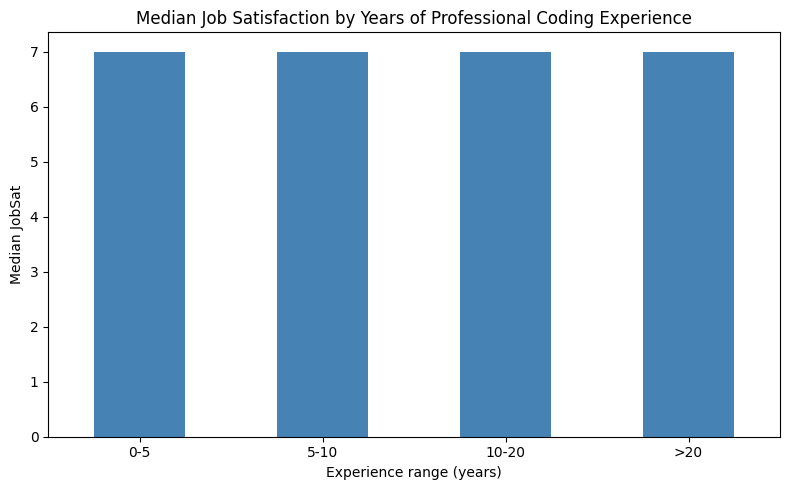

In [4]:
## Write your code here
# Helper: convert YearsCodePro (strings like 'Less than 1 year' / 'More than 50 years') to numeric
def to_years(val):
    if pd.isna(val):
        return None
    if isinstance(val, str):
        if val == 'Less than 1 year':
            return 0.5
        if val == 'More than 50 years':
            return 50
        try:
            return float(val)
        except ValueError:
            return None
    return float(val)

df['YearsCodePro_num'] = df['YearsCodePro'].apply(to_years)

# Create experience ranges
bins = [0, 5, 10, 20, float('inf')]
labels = ['0-5', '5-10', '10-20', '>20']
df['ExperienceRange'] = pd.cut(df['YearsCodePro_num'], bins=bins, labels=labels, right=False)

# Median JobSat for each range
median_sat = df.groupby('ExperienceRange', observed=True)['JobSat'].median()
print("Median JobSat by experience range:")
print(median_sat)

# Visualize with a bar plot
plt.figure(figsize=(8, 5))
median_sat.plot(kind='bar', color='steelblue')
plt.title('Median Job Satisfaction by Years of Professional Coding Experience')
plt.xlabel('Experience range (years)')
plt.ylabel('Median JobSat')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### Step 5: Visualize Job Satisfaction


Use a count plot to show the distribution of `JobSat` values. This provides insights into the overall satisfaction levels of respondents.


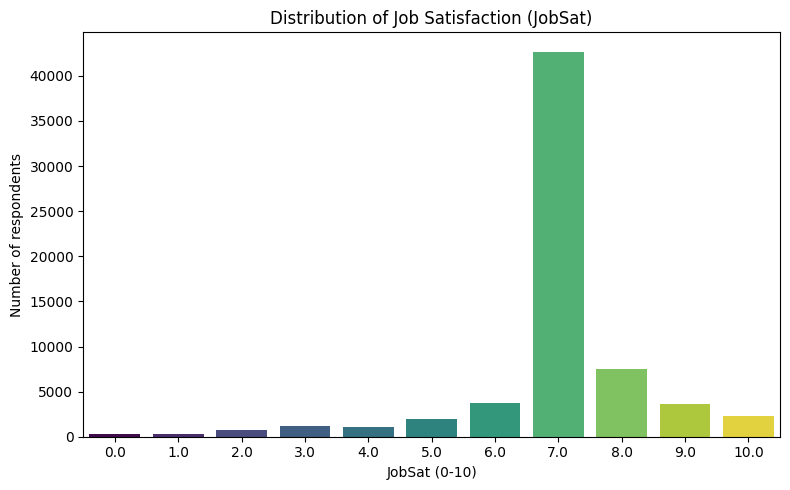

In [5]:
## Write your code here
plt.figure(figsize=(8, 5))
sns.countplot(x='JobSat', data=df, hue='JobSat', palette='viridis', legend=False)
plt.title('Distribution of Job Satisfaction (JobSat)')
plt.xlabel('JobSat (0-10)')
plt.ylabel('Number of respondents')
plt.tight_layout()
plt.show()

#### Step 6: Analyzing Remote Work Preferences by Job Role


Analyze trends in remote work based on job roles. Use the `RemoteWork` and `Employment` columns to explore preferences and examine if specific job roles prefer remote work more than others.

- Use a count plot to show remote work distribution.

- Cross-tabulate remote work preferences by employment type (e.g., full-time, part-time) and job roles.


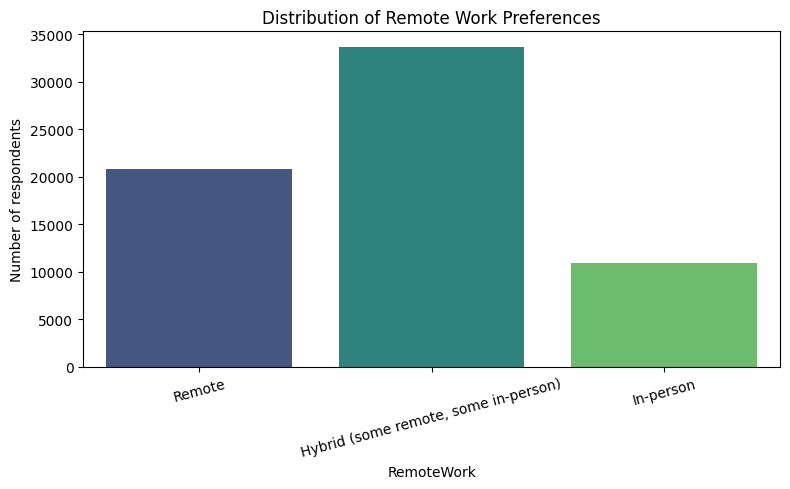


Cross-tabulation: RemoteWork x Employment
Employment                            Employed, full-time  \
RemoteWork                                                  
Hybrid (some remote, some in-person)                17296   
In-person                                            8552   
Remote                                              13193   

Employment                            Employed, full-time;Employed, part-time  \
RemoteWork                                                                      
Hybrid (some remote, some in-person)                                       85   
In-person                                                                  32   
Remote                                                                     95   

Employment                            Employed, full-time;Independent contractor, freelancer, or self-employed  \
RemoteWork                                                                                                       
Hybrid (some remo

In [6]:
## Write your code here
# Count plot of remote work distribution
plt.figure(figsize=(8, 5))
sns.countplot(x='RemoteWork', data=df, hue='RemoteWork', palette='viridis', legend=False)
plt.title('Distribution of Remote Work Preferences')
plt.xlabel('RemoteWork')
plt.ylabel('Number of respondents')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Cross-tabulate remote work preferences by employment type
print("\nCross-tabulation: RemoteWork x Employment")
print(pd.crosstab(df['RemoteWork'], df['Employment']))

#### Step 7: Analyzing Programming Language Trends by Region


Analyze the popularity of programming languages by region. Use the `LanguageHaveWorkedWith` column to investigate which languages are most used in different regions.

- Filter data by country or region.

- Visualize the top programming languages by region with a bar plot or heatmap.


                                             Country                Language  Count
                            United States of America              JavaScript   6849
                            United States of America                  Python   6238
                            United States of America                     SQL   5766
                            United States of America                HTML/CSS   5754
                            United States of America Bash/Shell (all shells)   4776
                                             Germany              JavaScript   2732
                                             Germany                  Python   2640
                                             Germany                HTML/CSS   2514
                                             Germany                     SQL   2297
                                             Germany Bash/Shell (all shells)   1970
                                               India              JavaScript

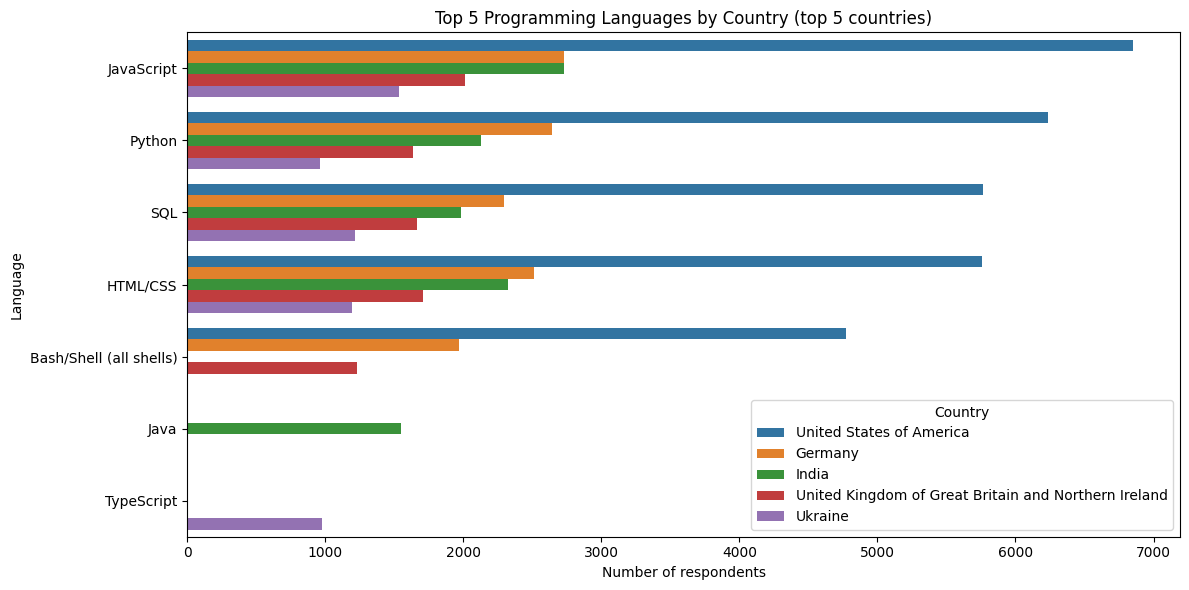

In [7]:
## Write your code here
# Investigate which languages are most used in different regions
# Top 5 countries by respondent count
top_countries = df['Country'].value_counts().head(5).index.tolist()

rows = []
for country in top_countries:
    subset = df[df['Country'] == country]
    langs = subset['LanguageHaveWorkedWith'].dropna().str.split(';').explode()
    counts = langs.value_counts().head(5)
    for lang, cnt in counts.items():
        rows.append({'Country': country, 'Language': lang, 'Count': cnt})

lang_df = pd.DataFrame(rows)
print(lang_df.to_string(index=False))

# Bar plot of top languages by region
plt.figure(figsize=(12, 6))
sns.barplot(data=lang_df, x='Count', y='Language', hue='Country')
plt.title('Top 5 Programming Languages by Country (top 5 countries)')
plt.xlabel('Number of respondents')
plt.ylabel('Language')
plt.tight_layout()
plt.show()

#### Step 8: Correlation Between Experience and Satisfaction


Examine how years of experience (`YearsCodePro`) correlate with job satisfaction (`JobSatPoints_1`). Use a scatter plot to visualize this relationship.


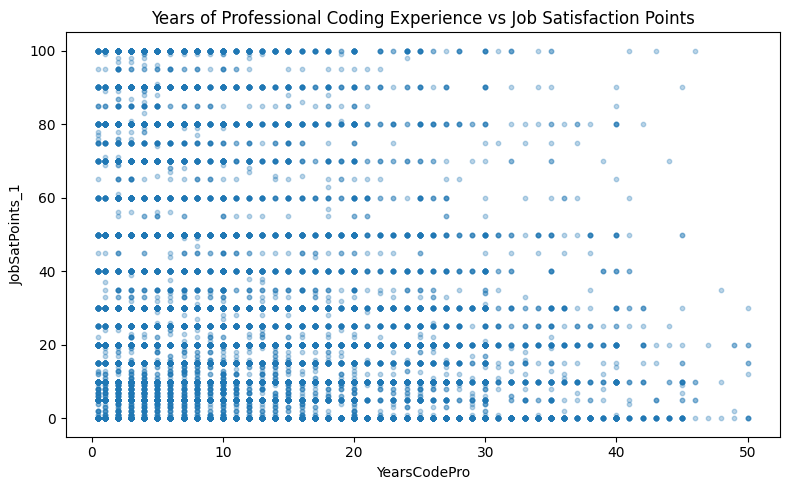

Correlation: -0.02846566319387142


In [8]:
## Write your code here
plt.figure(figsize=(8, 5))
plt.scatter(df['YearsCodePro_num'], df['JobSatPoints_1'], alpha=0.3, s=10)
plt.title('Years of Professional Coding Experience vs Job Satisfaction Points')
plt.xlabel('YearsCodePro')
plt.ylabel('JobSatPoints_1')
plt.tight_layout()
plt.show()

print("Correlation:", df[['YearsCodePro_num', 'JobSatPoints_1']].corr().iloc[0, 1])

#### Step 9: Educational Background and Employment Type


Explore how educational background (`EdLevel`) relates to employment type (`Employment`). Use cross-tabulation and visualizations to understand if higher education correlates with specific employment types.


Employment                                          Employed, full-time  \
EdLevel                                                                   
Associate degree (A.A., A.S., etc.)                                1059   
Bachelor’s degree (B.A., B.S., B.Eng., etc.)                      16806   
Master’s degree (M.A., M.S., M.Eng., MBA, etc.)                   11011   
Primary/elementary school                                           160   
Professional degree (JD, MD, Ph.D, Ed.D, etc.)                     2073   
Secondary school (e.g. American high school, Ge...                 1460   
Some college/university study without earning a...                 3579   
Something else                                                      377   

Employment                                          Employed, full-time;Employed, part-time  \
EdLevel                                                                                       
Associate degree (A.A., A.S., etc.)                        

C:\Users\Jerome\AppData\Local\Temp\ipykernel_16488\1013423803.py:13: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


<Figure size 1200x600 with 0 Axes>

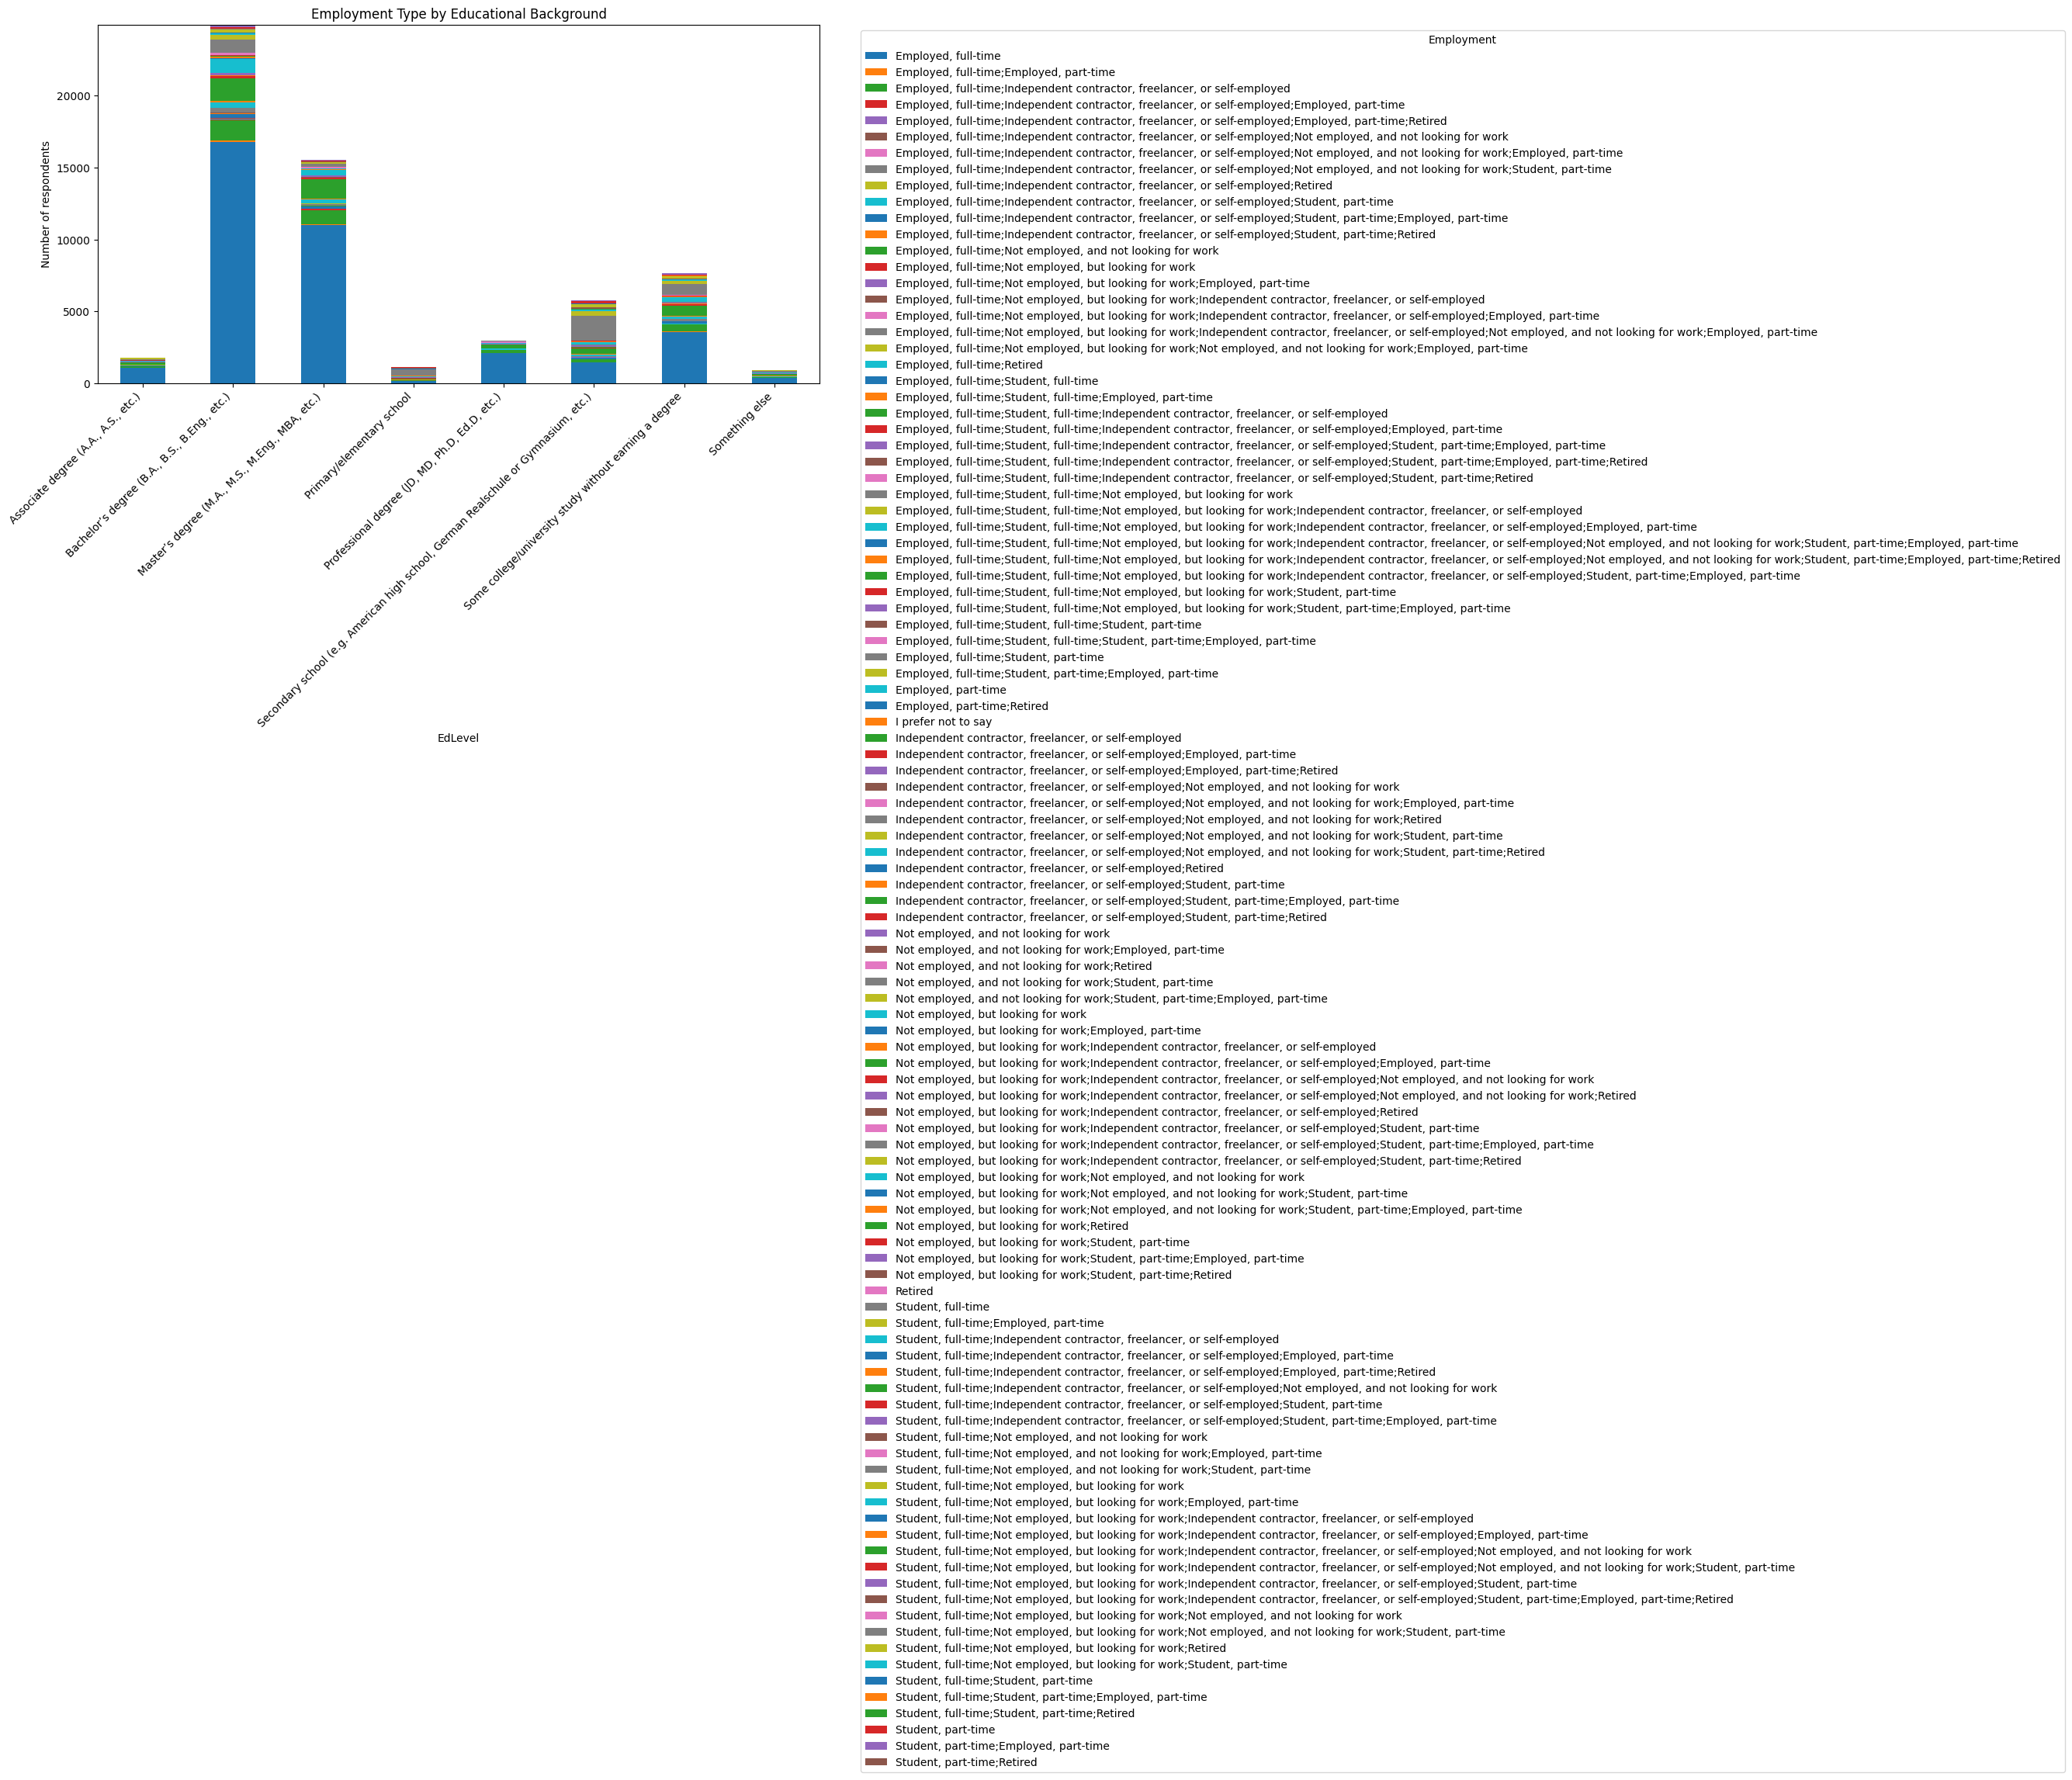

In [9]:
## Write your code here
# Cross-tabulation of EdLevel vs Employment
ct = pd.crosstab(df['EdLevel'], df['Employment'])
print(ct)

plt.figure(figsize=(12, 6))
ct.plot(kind='bar', stacked=True, figsize=(12, 6))
plt.title('Employment Type by Educational Background')
plt.xlabel('EdLevel')
plt.ylabel('Number of respondents')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Employment', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

#### Step 10: Save the Cleaned and Analyzed Dataset


After your analysis, save the modified dataset for further use or sharing.


In [10]:
## Write your code here
# Save the cleaned and analyzed dataset
output_file = 'survey_data_eda.csv'
df.to_csv(output_file, index=False)
print("Saved cleaned dataset to", output_file)
print("Shape:", df.shape)

Saved cleaned dataset to survey_data_eda.csv
Shape: (65437, 116)


<h2>Summary</h2>


In this revised lab, you:

- Loaded and explored the structure of the dataset.

- Handled missing data effectively.

- Analyzed key variables, including working hours, job satisfaction, and remote work trends.

- Investigated programming language usage by region and examined the relationship between experience and satisfaction.

- Used cross-tabulation to understand educational background and employment type.


Copyright © IBM Corporation. All rights reserved.
